# 04 – Baseline U-Net

In questo notebook utilizziamo la U-Net originale
del benchmark BRIGHT come prima baseline per la
segmentazione multimodale dei danni agli edifici.

L'obiettivo iniziale è verificare il funzionamento
del modello, prima di procedere all'addestramento
e alla valutazione su dati indipendenti.

In [1]:
from pathlib import Path
import sys
import torch

from bright_reproduction.models import crea_unet

ROOT = Path.cwd()
BRIGHT = ROOT / "BRIGHT"

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Interprete:", sys.executable)
print("Dispositivo:", device)
print("Directory:", ROOT)

Interprete: /Users/antonyogrossi/tesi/venv-tesi/bin/python
Dispositivo: mps
Directory: /Users/antonyogrossi/tesi/riproduzione_dfc2025


In [2]:
modello = crea_unet(BRIGHT).to(device)

num_parametri = sum(
    p.numel() for p in modello.parameters()
)

print("Modello:", type(modello).__name__)
print(f"Parametri: {num_parametri:,}")
print("Dispositivo:", next(modello.parameters()).device)

Modello: UNet
Parametri: 31,045,444
Dispositivo: mps:0


In [3]:
from bright_reproduction.data import BrightEsempiDataset
from torch.utils.data import DataLoader

CARTELLA_DATI = ROOT / "dati" / "bright_esempi"

identificativi = [
    "bata-explosion_00000049",
    "bata-explosion_00000014",
    "bata-explosion_00000047",
]

dataset = BrightEsempiDataset(
    CARTELLA_DATI,
    identificativi
)

loader = DataLoader(
    dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

batch = next(iter(loader))

print("Numero di esempi:", len(dataset))
print("Identificativo:", batch["id"])
print("Ottico:", batch["ottico"].shape)
print("SAR:", batch["sar"].shape)
print("Maschera:", batch["maschera"].shape)

Numero di esempi: 3
Identificativo: ['bata-explosion_00000049']
Ottico: torch.Size([1, 3, 1024, 1024])
SAR: torch.Size([1, 3, 1024, 1024])
Maschera: torch.Size([1, 1024, 1024])


In [4]:
from bright_reproduction.data import prepara_patch_centrale

DIM_PATCH = 128

input_modello, target, x, y = prepara_patch_centrale(
    batch,
    DIM_PATCH,
    device
)

print("Input:", input_modello.shape)
print("Target:", target.shape)
print("Classi presenti:", torch.unique(target).cpu().tolist())
print("Dispositivo:", input_modello.device)

Input: torch.Size([1, 6, 128, 128])
Target: torch.Size([1, 128, 128])
Classi presenti: [0, 3]
Dispositivo: mps:0


In [5]:
modello.eval()

with torch.no_grad():
    logits = modello(input_modello)

    previsione = torch.argmax(
        logits,
        dim=1
    )

print("Input:", input_modello.shape)
print("Logits:", logits.shape)
print("Previsione:", previsione.shape)
print("Classi predette:", torch.unique(previsione).cpu().tolist())
print("Logits finiti:", torch.isfinite(logits).all().item())

Input: torch.Size([1, 6, 128, 128])
Logits: torch.Size([1, 4, 128, 128])
Previsione: torch.Size([1, 128, 128])
Classi predette: [2]
Logits finiti: True


In [6]:
from bright_reproduction.data import prepara_target_loss

IGNORE_INDEX = 255

nome = batch["id"][0]

percorso_maschera = (
    CARTELLA_DATI / "target"
    / f"{nome}_building_damage.tif"
)

target_loss, nodata = prepara_target_loss(
    target,
    percorso_maschera,
    x,
    y,
    IGNORE_INDEX
)

print("NoData dichiarato:", nodata)
print("Pixel validi:", (target_loss != IGNORE_INDEX).sum().item())
print("Pixel ignorati:", (target_loss == IGNORE_INDEX).sum().item())

NoData dichiarato: None
Pixel validi: 16384
Pixel ignorati: 0


In [7]:
from torch import nn

criterio = nn.CrossEntropyLoss(
    ignore_index=IGNORE_INDEX
)

optimizer = torch.optim.AdamW(
    modello.parameters(),
    lr=1e-4
)

modello.train()

print("Loss:", type(criterio).__name__)
print("Optimizer:", type(optimizer).__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Loss: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.0001


In [8]:
from bright_reproduction.training import training_step

parametro = next(modello.parameters())
pesi_prima = parametro.detach().clone()

loss = training_step(
    modello,
    input_modello,
    target_loss,
    criterio,
    optimizer
)

variazione = (
    parametro.detach() - pesi_prima
).abs().mean().item()

print("Loss:", loss)
print("Gradienti finiti:", torch.isfinite(parametro.grad).all().item())
print("Variazione media dei pesi:", variazione)
print("Pesi aggiornati:", variazione > 0)

Loss: 1.5569207668304443
Gradienti finiti: True
Variazione media dei pesi: 0.00010000043403124437
Pesi aggiornati: True


## Addestramento di prova su una singola patch

L'obiettivo di questo esperimento è verificare
la capacità della U-Net di apprendere ripetutamente
dalla stessa coppia di immagini ottiche e SAR.

Si tratta di un test tecnico di overfitting,
non di una valutazione della capacità
di generalizzazione del modello.

In [9]:
from bright_reproduction.training import addestra_su_patch

NUM_ITERAZIONI = 30

storico_loss = addestra_su_patch(
    modello,
    input_modello,
    target_loss,
    criterio,
    optimizer,
    NUM_ITERAZIONI
)

print("Iterazioni:", len(storico_loss))
print("Loss iniziale:", storico_loss[0])
print("Loss finale:", storico_loss[-1])
print("Loss minima:", min(storico_loss))

Iterazioni: 30
Loss iniziale: 1.4216725826263428
Loss finale: 0.5988259315490723
Loss minima: 0.5988259315490723


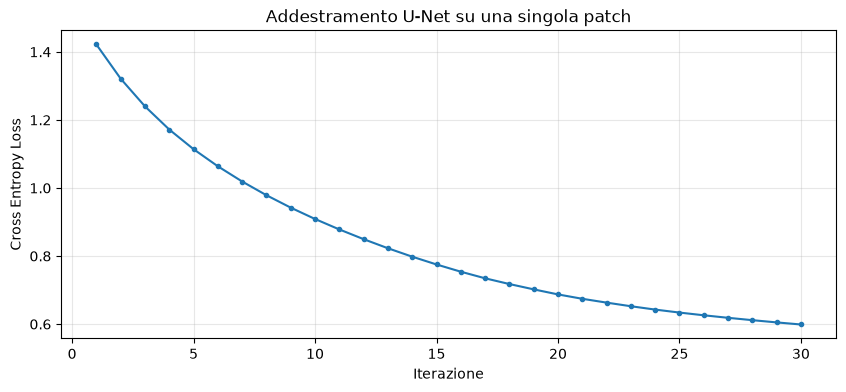

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.plot(
    range(1, len(storico_loss) + 1),
    storico_loss,
    marker="."
)

plt.xlabel("Iterazione")
plt.ylabel("Cross Entropy Loss")
plt.title("Addestramento U-Net su una singola patch")
plt.grid(alpha=0.3)
plt.show()

## Visualizzazione della previsione dopo l'addestramento

Confrontiamo la previsione della U-Net con la
maschera reale della patch utilizzata durante
l'addestramento.

L'obiettivo è verificare qualitativamente se il
modello riesce a riconoscere lo sfondo e gli
edifici distrutti.

Non si tratta di una valutazione su dati indipendenti.

In [11]:
modello.eval()

with torch.no_grad():

    logits_finali = modello(input_modello)

    previsione_finale = torch.argmax(
        logits_finali,
        dim=1
    )

    loss_eval = criterio(
        logits_finali,
        target_loss
    ).item()

print("Dimensioni:", previsione_finale.shape)
print("Classi predette:", torch.unique(previsione_finale).cpu().tolist())
print("Loss in modalità eval:", loss_eval)

Dimensioni: torch.Size([1, 128, 128])
Classi predette: [0, 1, 2, 3]
Loss in modalità eval: 1.0284428596496582


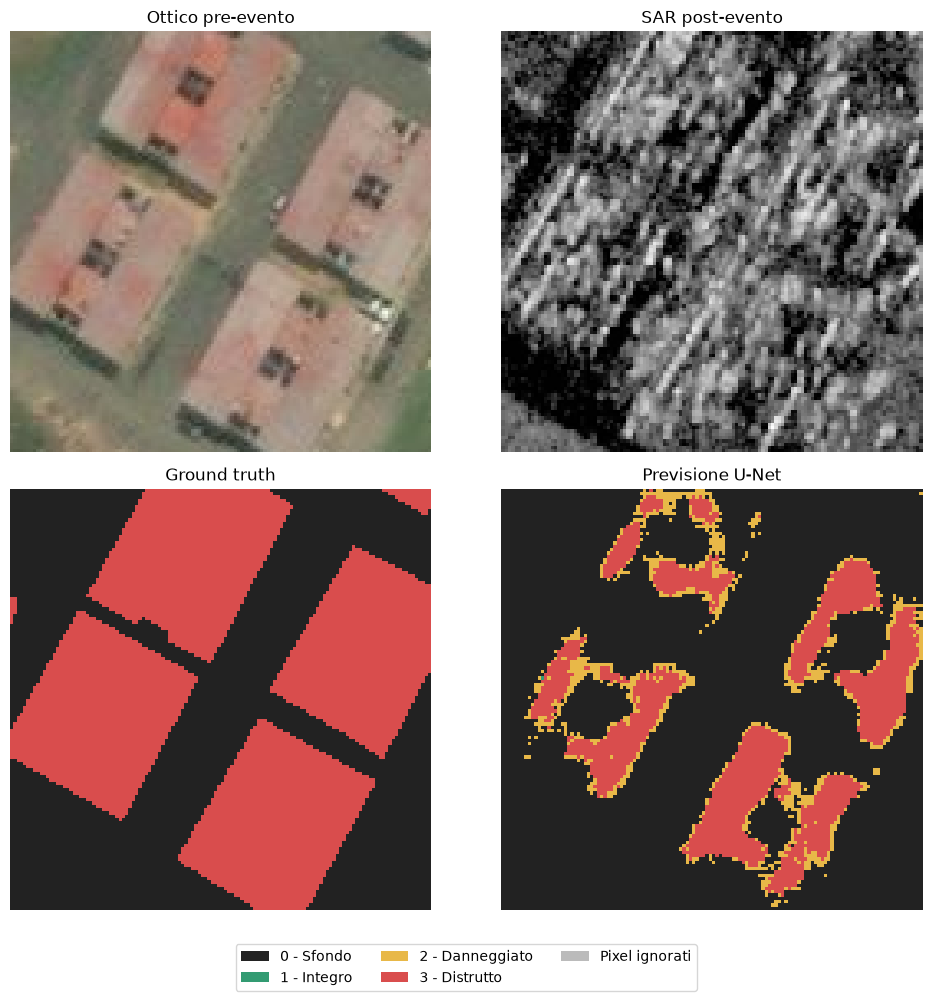

In [12]:
from bright_reproduction.visualization import (
    visualizza_previsione_patch
)

fig = visualizza_previsione_patch(
    input_modello,
    target_loss,
    previsione_finale
)

plt.show()

## Valutazione quantitativa della previsione

Utilizziamo le metriche implementate nel notebook 03
per valutare la previsione della U-Net sulla patch
di addestramento.

Confrontiamo il modello con una previsione di
controllo che assegna tutti i pixel allo sfondo.

Le metriche sono diagnostiche e non rappresentano
il punteggio ufficiale del DFC2025 Track 2.

In [18]:
from bright_reproduction.metriche import valuta_previsione

import numpy as np
import pandas as pd

riferimento = target_loss.cpu().numpy()
predizione = previsione_finale.cpu().numpy()

matrice, tabella, riepilogo = valuta_previsione(
    riferimento,
    predizione,
    IGNORE_INDEX
)

display(tabella.round(4))

print("Matrice di confusione:")
print(matrice)

,Pixel reali,Pixel predetti,IoU,F1
Classe,,,,
Sfondo,8195,12428,0.6525,0.7897
Integro,0,1,0.0000,0.0000
Danneggiato,0,1108,0.0000,0.0000
Distrutto,8189,2847,0.3465,0.5147


Matrice di confusione:
[[8143    0   45    7]
 [   0    0    0    0]
 [   0    0    0    0]
 [4285    1 1063 2840]]


In [20]:
sempre_sfondo = np.zeros_like(riferimento)

_, tabella_sfondo, riepilogo_sfondo = valuta_previsione(
    riferimento,
    sempre_sfondo,
    IGNORE_INDEX
)

confronto = pd.DataFrame({
    "U-Net": riepilogo,
    "Sempre sfondo": riepilogo_sfondo
}).T

display((confronto * 100).round(2))

,Accuracy,mIoU diagnostica,mIoU 4 classi,mIoU classi presenti,F1 edificio
U-Net,67.03,24.97,24.97,49.95,64.29
Sempre sfondo,50.02,25.01,12.50,25.01,0.00


## Salvataggio del checkpoint

Salviamo il modello ottenuto dopo 31 aggiornamenti
dei pesi sulla singola patch di addestramento.

Il checkpoint rappresenta un esperimento tecnico
preliminare di overfitting e non un modello
validato su dati indipendenti.

In [ ]:
import subprocess
import bright_reproduction.training as training

configurazione = {
    "modello": "UNet BRIGHT",
    "in_channels": 6,
    "num_classes": 4,
    "device": str(device),
    "seed": 42,
    "batch_size": 1,
    "patch_size": DIM_PATCH,
    "patch_x": x,
    "patch_y": y,
    "learning_rate": optimizer.param_groups[0]["lr"],
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss",
    "ignore_index": IGNORE_INDEX,
    "train_id": nome,
    "training_steps": NUM_ITERAZIONI + 1,
    "torch_version": str(torch.__version__),
    "commit_progetto_base": subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=ROOT,
        text=True
    ).strip(),
    "commit_bright": subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=BRIGHT,
        text=True
    ).strip(),
    "tipo_esperimento": "overfitting_singola_patch"
}

percorso_checkpoint = training.salva_checkpoint(
    ROOT / "checkpoints" / "unet_overfit_patch.pt",
    modello,
    optimizer,
    configurazione,
    storico_loss
)

print("Checkpoint salvato:", percorso_checkpoint)

print(
    "Dimensione:",
    round(percorso_checkpoint.stat().st_size / 1024**2, 2),
    "MiB"
)

Checkpoint salvato: /Users/antonyogrossi/tesi/riproduzione_dfc2025/checkpoints/unet_overfit_patch.pt
Dimensione: 355.44 MiB


In [23]:
checkpoint = torch.load(
    percorso_checkpoint,
    map_location="cpu",
    weights_only=True
)

modello_caricato = crea_unet(BRIGHT)

modello_caricato.load_state_dict(
    checkpoint["model_state_dict"]
)

modello_caricato = modello_caricato.to(device)
modello_caricato.eval()

with torch.no_grad():
    logits_caricati = modello_caricato(input_modello)

    previsione_caricata = logits_caricati.argmax(dim=1)

print(
    "Previsioni identiche:",
    torch.equal(previsione_finale, previsione_caricata)
)

print(
    "Logits equivalenti:",
    torch.allclose(logits_finali, logits_caricati)
)

Previsioni identiche: True
Logits equivalenti: True
